In [1]:
import glob
import regex as re
from tqdm.auto import tqdm
import pandas as pd
import numpy as np
from sklearn.metrics import classification_report
from matplotlib import pyplot as plt
import mpl_toolkits.axisartist.axislines as axislines

from scipy import stats

C:\Users\isen1\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


In [2]:
# annotations were run separately for each simulated model
# (results of the earlier mixed pre-/post-election design are in results/mixed_pre_post)
df = pd.concat([
    pd.read_csv(f, low_memory=False)
    for f in sorted(glob.glob('results/pre_election/annotated_GLM-4.7-Flash_*.zst'))
], ignore_index=True)
df

,questionnaire_name,questionnaire_item_id,question,llm_response,logprobs,reasoning,response_type,persona_format,persona_id,sample,model_id,seed,answer
0,openResponse_firstPerson_0_0,1,Will you vote in the 2024 U.S. presidential el...,"Based on the information provided, I would pre...",NaN,NaN,openResponse,firstPerson,0,0,Llama-3.1-8B-Instruct,42,Trump
1,openResponse_firstPerson_0_0,2,Please tell me if you will vote and if so for ...,"Based on the information provided, I would pre...",NaN,NaN,openResponse,firstPerson,0,0,Llama-3.1-8B-Instruct,42,Trump
2,openResponse_firstPerson_1_0,1,Will you vote in the 2024 U.S. presidential el...,"Based on the information provided, I would pre...",NaN,NaN,openResponse,firstPerson,1,0,Llama-3.1-8B-Instruct,42,Harris
3,openResponse_firstPerson_1_0,2,Please tell me if you will vote and if so for ...,"Based on the information provided, I'm going t...",NaN,NaN,openResponse,firstPerson,1,0,Llama-3.1-8B-Instruct,42,Harris
4,openResponse_firstPerson_2_0,1,Will you vote in the 2024 U.S. presidential el...,I cannot predict the outcome of a specific ele...,NaN,NaN,openResponse,firstPerson,2,0,Llama-3.1-8B-Instruct,42,Non-voter
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2434075,jsonResponse_demogrInterview_5068_0,2,Please tell me if you will vote and if so for ...,NaN,NaN,NaN,jsonResponse,demogrInterview,5068,0,Qwen3-VL-8B-Instruct,46,Harris
2434076,jsonResponse_demogrInterview_5069_0,1,Will you vote in the 2024 U.S. presidential el...,NaN,NaN,NaN,jsonResponse,demogrInterview,5069,0,Qwen3-VL-8B-Instruct,46,Harris
2434077,jsonResponse_demogrInterview_5069_0,2,Please tell me if you will vote and if so for ...,NaN,NaN,NaN,jsonResponse,demogrInterview,5069,0,Qwen3-VL-8B-Instruct,46,Harris
2434078,jsonResponse_demogrInterview_5070_0,1,Will you vote in the 2024 U.S. presidential el...,NaN,NaN,NaN,jsonResponse,demogrInterview,5070,0,Qwen3-VL-8B-Instruct,46,Trump


In [3]:
df.columns

Index(['questionnaire_name', 'questionnaire_item_id', 'question',
       'llm_response', 'logprobs', 'reasoning', 'response_type',
       'persona_format', 'persona_id', 'sample', 'model_id', 'seed', 'answer'],
      dtype='object')

In [4]:
df['seed'].unique()

array([42, 43, 44, 45, 46], dtype=int64)

In [5]:
df['regex_answer'] = df.llm_response.str.extract(r'(Trump|Harris|Non-voter)', expand=False)

In [6]:
# add parsing method to specifications
df_regex = df.melt(
    id_vars=[c for c in df.columns if "answer" not in c],
    value_vars=['answer', 'regex_answer'],
    value_name='parsed_answer',
    var_name='parsing_method'
)
df_regex['parsing_method'] = df_regex.parsing_method.replace({'answer': 'LLMjudge', 'regex_answer': 'regex'})

# regex parsing is not applicable to json responses
df_regex = df_regex[
    ~((df_regex.response_type == 'jsonResponse') & (df_regex.parsing_method == 'regex'))
]
df_regex.loc[
    df_regex.response_type == 'jsonResponse',
    'parsing_method'
] = 'jsonParsing'

# convert parsed_answer to str even if regex parsing might have failed
# we define the set of "accepted" labels below to properly handle invalid responses
df_regex['parsed_answer'] = df_regex['parsed_answer'].astype(str)

df_regex

,questionnaire_name,questionnaire_item_id,question,llm_response,logprobs,reasoning,response_type,persona_format,persona_id,sample,model_id,seed,parsing_method,parsed_answer
0,openResponse_firstPerson_0_0,1,Will you vote in the 2024 U.S. presidential el...,"Based on the information provided, I would pre...",NaN,NaN,openResponse,firstPerson,0,0,Llama-3.1-8B-Instruct,42,LLMjudge,Trump
1,openResponse_firstPerson_0_0,2,Please tell me if you will vote and if so for ...,"Based on the information provided, I would pre...",NaN,NaN,openResponse,firstPerson,0,0,Llama-3.1-8B-Instruct,42,LLMjudge,Trump
2,openResponse_firstPerson_1_0,1,Will you vote in the 2024 U.S. presidential el...,"Based on the information provided, I would pre...",NaN,NaN,openResponse,firstPerson,1,0,Llama-3.1-8B-Instruct,42,LLMjudge,Harris
3,openResponse_firstPerson_1_0,2,Please tell me if you will vote and if so for ...,"Based on the information provided, I'm going t...",NaN,NaN,openResponse,firstPerson,1,0,Llama-3.1-8B-Instruct,42,LLMjudge,Harris
4,openResponse_firstPerson_2_0,1,Will you vote in the 2024 U.S. presidential el...,I cannot predict the outcome of a specific ele...,NaN,NaN,openResponse,firstPerson,2,0,Llama-3.1-8B-Instruct,42,LLMjudge,Non-voter
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4665315,openResponse_demogrInterview_5068_0,2,Please tell me if you will vote and if so for ...,"I will vote for Harris.\n\nAs a White, 69-year...",NaN,NaN,openResponse,demogrInterview,5068,0,Qwen3-VL-8B-Instruct,46,regex,Harris
4665316,openResponse_demogrInterview_5069_0,1,Will you vote in the 2024 U.S. presidential el...,Harris.\n\nAs a 28-year-old Black male from Ne...,NaN,NaN,openResponse,demogrInterview,5069,0,Qwen3-VL-8B-Instruct,46,regex,Harris
4665317,openResponse_demogrInterview_5069_0,2,Please tell me if you will vote and if so for ...,Harris. \n\nAs a young Black male from New Jer...,NaN,NaN,openResponse,demogrInterview,5069,0,Qwen3-VL-8B-Instruct,46,regex,Harris
4665318,openResponse_demogrInterview_5070_0,1,Will you vote in the 2024 U.S. presidential el...,Trump\n\n*Note: As a political scientist predi...,NaN,NaN,openResponse,demogrInterview,5070,0,Qwen3-VL-8B-Instruct,46,regex,Trump


In [7]:
anes_df = pd.read_csv('data/2024_anes_pre-election_preprocessed.csv', index_col=0).reset_index(names='ANES_index')
anes_df['age_bracket'] = (anes_df.age // 10) * 10
anes_df

,ANES_index,anes_id,mode,pre_weight,post_weight,age,political_attention,race,ideology,party,attend_church,gender,campaign_interest,state,vote_intent_summary,turnout_likelihood,reported_turnout,reported_vote,vote_choice,age_bracket
0,0,140001,2,0.716602,0.710865,50.0,pay attention to what's going on in government...,Hispanic,conservative,a strong Republican,True,male,very much,Oklahoma,21,2,1,Trump,Trump,50.0
1,2,140003,2,0.780178,0.808992,44.0,pay attention to what's going on in government...,White,liberal,a strong Democrat,False,female,very much,Virginia,20,2,1,Harris,Harris,40.0
2,3,140004,2,0.268988,0.291740,45.0,pay attention to what's going on in government...,Asian,NaN,a weak Republican,True,male,somewhat,California,21,4,0,Non-voter,Trump,40.0
3,4,140005,2,0.244306,0.222012,80.0,pay attention to what's going on in government...,White,moderate,an independent who leans Republican,False,male,somewhat,Colorado,21,3,1,Trump,Trump,80.0
4,5,140006,2,0.498597,0.472275,75.0,always pay attention to what's going on in gov...,White,moderate,an independent who leans Democratic,False,female,very much,Texas,20,2,0,Non-voter,Harris,70.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5066,5515,399579,1,0.115966,0.075758,80.0,pay attention to what's going on in government...,Hispanic,slightly liberal,an independent who leans Democratic,False,female,very much,Colorado,20,2,1,Harris,Harris,80.0
5067,5516,399764,1,0.193087,NaN,NaN,pay attention to what's going on in government...,NaN,moderate,an independent,True,female,not much,California,-2,5,-2,NaN,Non-voter,NaN
5068,5517,399815,1,2.910370,1.797863,69.0,always pay attention to what's going on in gov...,White,slightly liberal,a weak Democrat,True,female,very much,Minnesota,20,2,1,Harris,Harris,60.0
5069,5519,399841,4,2.635201,2.255936,28.0,pay attention to what's going on in government...,Black,extremely liberal,a strong Democrat,False,male,very much,New Jersey,20,2,1,Harris,Harris,20.0


In [8]:
comb_df = pd.merge(
    left = df_regex,
    right = anes_df,
    left_on = 'persona_id',
    right_index = True,
    how = 'left'
)
comb_df.head()

,questionnaire_name,questionnaire_item_id,question,llm_response,logprobs,reasoning,response_type,persona_format,persona_id,sample,...,attend_church,gender,campaign_interest,state,vote_intent_summary,turnout_likelihood,reported_turnout,reported_vote,vote_choice,age_bracket
0,openResponse_firstPerson_0_0,1,Will you vote in the 2024 U.S. presidential el...,"Based on the information provided, I would pre...",NaN,NaN,openResponse,firstPerson,0,0,...,True,male,very much,Oklahoma,21,2,1,Trump,Trump,50.0
1,openResponse_firstPerson_0_0,2,Please tell me if you will vote and if so for ...,"Based on the information provided, I would pre...",NaN,NaN,openResponse,firstPerson,0,0,...,True,male,very much,Oklahoma,21,2,1,Trump,Trump,50.0
2,openResponse_firstPerson_1_0,1,Will you vote in the 2024 U.S. presidential el...,"Based on the information provided, I would pre...",NaN,NaN,openResponse,firstPerson,1,0,...,False,female,very much,Virginia,20,2,1,Harris,Harris,40.0
3,openResponse_firstPerson_1_0,2,Please tell me if you will vote and if so for ...,"Based on the information provided, I'm going t...",NaN,NaN,openResponse,firstPerson,1,0,...,False,female,very much,Virginia,20,2,1,Harris,Harris,40.0
4,openResponse_firstPerson_2_0,1,Will you vote in the 2024 U.S. presidential el...,I cannot predict the outcome of a specific ele...,NaN,NaN,openResponse,firstPerson,2,0,...,True,male,somewhat,California,21,4,0,Non-voter,Trump,40.0


In [9]:
comb_df

,questionnaire_name,questionnaire_item_id,question,llm_response,logprobs,reasoning,response_type,persona_format,persona_id,sample,...,attend_church,gender,campaign_interest,state,vote_intent_summary,turnout_likelihood,reported_turnout,reported_vote,vote_choice,age_bracket
0,openResponse_firstPerson_0_0,1,Will you vote in the 2024 U.S. presidential el...,"Based on the information provided, I would pre...",NaN,NaN,openResponse,firstPerson,0,0,...,True,male,very much,Oklahoma,21,2,1,Trump,Trump,50.0
1,openResponse_firstPerson_0_0,2,Please tell me if you will vote and if so for ...,"Based on the information provided, I would pre...",NaN,NaN,openResponse,firstPerson,0,0,...,True,male,very much,Oklahoma,21,2,1,Trump,Trump,50.0
2,openResponse_firstPerson_1_0,1,Will you vote in the 2024 U.S. presidential el...,"Based on the information provided, I would pre...",NaN,NaN,openResponse,firstPerson,1,0,...,False,female,very much,Virginia,20,2,1,Harris,Harris,40.0
3,openResponse_firstPerson_1_0,2,Please tell me if you will vote and if so for ...,"Based on the information provided, I'm going t...",NaN,NaN,openResponse,firstPerson,1,0,...,False,female,very much,Virginia,20,2,1,Harris,Harris,40.0
4,openResponse_firstPerson_2_0,1,Will you vote in the 2024 U.S. presidential el...,I cannot predict the outcome of a specific ele...,NaN,NaN,openResponse,firstPerson,2,0,...,True,male,somewhat,California,21,4,0,Non-voter,Trump,40.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4665315,openResponse_demogrInterview_5068_0,2,Please tell me if you will vote and if so for ...,"I will vote for Harris.\n\nAs a White, 69-year...",NaN,NaN,openResponse,demogrInterview,5068,0,...,True,female,very much,Minnesota,20,2,1,Harris,Harris,60.0
4665316,openResponse_demogrInterview_5069_0,1,Will you vote in the 2024 U.S. presidential el...,Harris.\n\nAs a 28-year-old Black male from Ne...,NaN,NaN,openResponse,demogrInterview,5069,0,...,False,male,very much,New Jersey,20,2,1,Harris,Harris,20.0
4665317,openResponse_demogrInterview_5069_0,2,Please tell me if you will vote and if so for ...,Harris. \n\nAs a young Black male from New Jer...,NaN,NaN,openResponse,demogrInterview,5069,0,...,False,male,very much,New Jersey,20,2,1,Harris,Harris,20.0
4665318,openResponse_demogrInterview_5070_0,1,Will you vote in the 2024 U.S. presidential el...,Trump\n\n*Note: As a political scientist predi...,NaN,NaN,openResponse,demogrInterview,5070,0,...,True,female,somewhat,Tennessee,21,3,1,Trump,Trump,30.0


In [10]:
comb_df['parsed_answer'].unique()

array(['Trump', 'Harris', 'Non-voter', 'nan'], dtype=object)

In [11]:
comb_df.columns

Index(['questionnaire_name', 'questionnaire_item_id', 'question',
       'llm_response', 'logprobs', 'reasoning', 'response_type',
       'persona_format', 'persona_id', 'sample', 'model_id', 'seed',
       'parsing_method', 'parsed_answer', 'ANES_index', 'anes_id', 'mode',
       'pre_weight', 'post_weight', 'age', 'political_attention', 'race',
       'ideology', 'party', 'attend_church', 'gender', 'campaign_interest',
       'state', 'vote_intent_summary', 'turnout_likelihood',
       'reported_turnout', 'reported_vote', 'vote_choice', 'age_bracket'],
      dtype='object')

In [12]:
comb_df[comb_df['parsed_answer'] == 'nan'].groupby(['model_id', 'parsing_method']).size()

model_id                   parsing_method
Llama-3.1-8B-Instruct      regex             10414
Llama-3.3-70B-Instruct     regex                17
Olmo-3-7B-Instruct         regex              4611
Olmo-3.1-32B-Instruct      regex             14872
Qwen3-VL-30B-A3B-Instruct  regex               232
Qwen3-VL-8B-Instruct       regex                 1
dtype: int64

In [13]:
comb_df[comb_df['parsed_answer'] == 'nan']['llm_response'].values

array(['I cannot predict the outcome of a specific election. Is there anything else I can help you with?',
       'I cannot predict the outcome of a specific election. Is there anything else I can help you with?',
       'I cannot predict a real vote. Is there something else I can help you with?',
       ...,
       'I am not a registered voter, so I will not be participating in the 2024 U.S. presidential election.',
       'I am not going to vote.',
       'I’m 18, so I’m not yet eligible to vote in the 2024 U.S. presidential election — Missouri’s voting age is 18, but I haven’t reached it yet. I’m currently registered as a non-voter, and I’ll be focusing on getting informed and ready to vote in 2028.\n\n*(Note: If the interviewee were eligible, their answer would depend on their political views, which this data alone does not determine. But based on their age and identity, they cannot vote this year.)*'],
      dtype=object)

### for reliability, f1 and tvd for each ofthe 144 configurations over 5 different seeds

In [14]:
### Calculate metrics for each simulation specification

specification_cols = [
    'questionnaire_item_id',
    'response_type',
    'persona_format',
    'sample',
    'model_id',
    'parsing_method'
]

demographic_cols = [
    'age_bracket',
    'political_attention',
    'race',
    'ideology',
    'party',
    'attend_church',
    'gender',
    'campaign_interest',
    'state'
]

labels = ['Trump', 'Harris', 'Non-voter']

agg_results = []
count = 0

for group_spec, group_df in tqdm(comb_df.groupby(specification_cols)):
    group_results = dict(zip(specification_cols, group_spec))

    
    # disaggregate by seed
    for seed, group_df_seed in group_df.groupby('seed'):
    
        count += 1
        last_df = group_df_seed

        ### Individual-level accuracy
        report = classification_report(
            group_df_seed['vote_choice'],
            group_df_seed['parsed_answer'],
            labels=labels,
            output_dict=True,
            zero_division=0, # handle non-existing labels
        )

        # pre_weight matches the pre-election persona and vote intention
        # NOTE that weights mean something slightly different than in surveys
        weighted_report = classification_report(
            group_df_seed['vote_choice'],
            group_df_seed['parsed_answer'],
            labels=labels,
            output_dict=True,
            sample_weight=group_df_seed['pre_weight'],
            zero_division=0, # handle non-existing labels
        )

        ### Marginal distributions
        tvds = []
        weighted_tvds = []
        f1s = []
        for dem_col in demographic_cols:
            for dem_val, subgroup in group_df_seed.groupby(dem_col):

                # Ignore survey weights and just count vote choices
                true_vals = subgroup.groupby('vote_choice')['pre_weight'].count()
                # Fill-in zeros for labels that did not occur and normalize
                true_dist = pd.Series({
                    label: true_vals.get(label, default=0) / true_vals.sum()
                    for label in labels
                })
                pred_vals = subgroup.groupby('parsed_answer')['pre_weight'].count()
                # Fill-in zeros for labels that did not occur and normalize
                pred_dist = pd.Series({
                    label: pred_vals.get(label, default=0) / pred_vals.sum()
                    for label in labels
                })

                tvds.append({
                    'subgroup' : dem_col,
                    'subgroup category': dem_val,
                    'subgroup_size': len(subgroup),
                    'tvd': 0.5 * np.abs(true_dist - pred_dist).sum(),
                })
                
                # Account for survey weights by calculating the sum
                true_weighted_vals = subgroup.groupby('vote_choice')['pre_weight'].sum() # <- the sum() is crucial
                # Fill-in zeros for labels that did not occur and normalize
                true_weighted_dist = pd.Series({
                    label: true_weighted_vals.get(label, default=0) / true_weighted_vals.sum()
                    for label in labels
                })
                pred_weighted_vals = subgroup.groupby('parsed_answer')['pre_weight'].sum()
                # Fill-in zeros for labels that did not occur and normalize
                pred_weighted_dist = pd.Series({
                    label: pred_weighted_vals.get(label, default=0) / pred_weighted_vals.sum()
                    for label in labels
                })

                weighted_tvds.append({
                    'subgroup' : dem_col,
                    'subgroup category': dem_val,
                    'subgroup_size': len(subgroup),
                    'tvd': 0.5 * np.abs(true_weighted_dist - pred_weighted_dist).sum(),
                })
                
                
            
            
        tvd_df = pd.DataFrame(tvds)
        weighted_tvd_df = pd.DataFrame(weighted_tvds)
        f1_df = pd.DataFrame(f1s)

        ### Combine the evaluation results into a report
        group_results = group_results | {
            'seed': seed,
            'simulated_responses': len(group_df_seed),
            'valid_responses': len(group_df_seed[group_df_seed.parsed_answer != 'nan']),
        
            # accuracy can be nan if values could not be parsed
            'accuracy': report['accuracy'] if 'accuracy' in report else np.nan,
            'weighted_accuracy': weighted_report['accuracy'] if 'accuracy' in weighted_report else np.nan,

            'macro_avg_f1': report['macro avg']['f1-score'],
            'nonadjusted_weighted_f1': report['weighted avg']['f1-score'],
            'adjusted_weighted_f1': weighted_report['weighted avg']['f1-score'],
        }

        # Add unweighted & weighted Total Variation Distance, optionally ignore subgroups that are too small
        for cutoff in [0, 10, 50, 100]:
            if cutoff == 0: cutoff_str = ''
            else: cutoff_str = str(cutoff)

            group_results = group_results | {
                # TVD without accounting for survey weights
                f'nonadjusted_weighted{cutoff_str}_avg': tvd_df[tvd_df.subgroup_size >= cutoff]['tvd'].mean(),
                f'nonadjusted_weighted{cutoff_str}_std': tvd_df[tvd_df.subgroup_size >= cutoff]['tvd'].std(),

                # TVD based on weighted distributions
                f'adjusted_weighted{cutoff_str}_avg': weighted_tvd_df[weighted_tvd_df.subgroup_size >= cutoff]['tvd'].mean(),
                f'adjusted_weighted{cutoff_str}_std': weighted_tvd_df[weighted_tvd_df.subgroup_size >= cutoff]['tvd'].std(),
            }
    
        agg_results.append(group_results)

agg_results_df = pd.DataFrame(agg_results)
count

  0%|          | 0/144 [00:00<?, ?it/s]

720

In [15]:
metrics_of_interest = ['nonadjusted_weighted_f1', 'adjusted_weighted_f1', 'nonadjusted_weighted_avg', 'adjusted_weighted_avg']
configs = []

for _, row in agg_results_df.iterrows():
    configs.append(' '.join([str(row[category]) for category in specification_cols]))
    
unique_configs = list(set(configs))
config_mapping = {}
for n, configuration in enumerate(unique_configs):
    config_mapping[configuration] = n
    
agg_results_df['configuration'] = configs
agg_results_df['configuration_id'] = [config_mapping[i] for i in configs]

In [16]:
agg_results_df.groupby('configuration_id')[metrics_of_interest].std().mean()

nonadjusted_weighted_f1     0.002871
adjusted_weighted_f1        0.004288
nonadjusted_weighted_avg    0.003031
adjusted_weighted_avg       0.003794
dtype: float64

In [17]:
import seaborn as sns
sns.set_context('paper')

In [18]:
metric = 'adjusted_weighted_f1'

In [19]:
sort_order = agg_results_df.groupby('configuration_id')[metric].mean().sort_values().index # sort by mean metric score

C:\Users\isen1\AppData\Local\Temp\ipykernel_15164\4029712779.py:3: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0. You can remove the line between points with `linestyle='none'`.

  ax = sns.pointplot(y = 'adjusted_weighted_avg',
C:\Users\isen1\AppData\Local\Temp\ipykernel_15164\4029712779.py:11: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0. You can remove the line between points with `linestyle='none'`.

  ax = sns.pointplot(y = 'adjusted_weighted_f1',


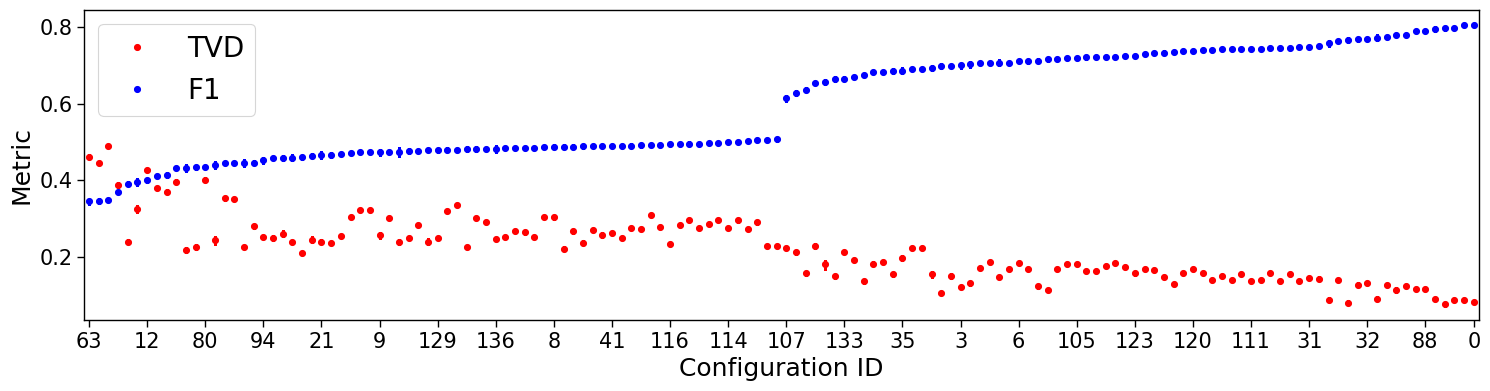

In [20]:
plt.figure(figsize=(15,4))

ax = sns.pointplot(y = 'adjusted_weighted_avg',
              x = 'configuration_id',
              data = agg_results_df,
              order = sort_order,
              color = 'red',
              label = 'TVD',
              join = False,
              markersize=3.5)
ax = sns.pointplot(y = 'adjusted_weighted_f1',
              x = 'configuration_id',
              data = agg_results_df,
              order = sort_order,
              label = 'F1',
              color = 'blue',
              join = False,
              # dodge=.4,
              markersize=3.5)

ax.set_ylabel('Metric', fontsize=18)
ax.set_xlabel("Configuration ID",fontsize=18)
ax.tick_params(labelsize=15)

plt.xticks([n for n, i in enumerate(sort_order) if n%6 == 0 or n == 143])
plt.legend(fontsize = 20)
plt.tight_layout()
plt.savefig('results/pre_election/reliability.pdf', dpi = 300)

In [22]:
agg_results_df

,questionnaire_item_id,response_type,persona_format,sample,model_id,parsing_method,seed,simulated_responses,valid_responses,accuracy,...,nonadjusted_weighted50_avg,nonadjusted_weighted50_std,adjusted_weighted50_avg,adjusted_weighted50_std,nonadjusted_weighted100_avg,nonadjusted_weighted100_std,adjusted_weighted100_avg,adjusted_weighted100_std,configuration,configuration_id
0,1,jsonResponse,demogrFirstPerson,0,Llama-3.1-8B-Instruct,jsonParsing,42,5071,5071,0.506409,...,0.322056,0.134213,0.290200,0.126799,0.314025,0.132332,0.282456,0.119867,1 jsonResponse demogrFirstPerson 0 Llama-3.1-8...,22
1,1,jsonResponse,demogrFirstPerson,0,Llama-3.1-8B-Instruct,jsonParsing,43,5071,5071,0.512325,...,0.325326,0.133973,0.288773,0.127062,0.316551,0.132531,0.282294,0.119391,1 jsonResponse demogrFirstPerson 0 Llama-3.1-8...,22
2,1,jsonResponse,demogrFirstPerson,0,Llama-3.1-8B-Instruct,jsonParsing,44,5071,5071,0.515283,...,0.319253,0.131410,0.283627,0.122430,0.310997,0.130670,0.275661,0.116195,1 jsonResponse demogrFirstPerson 0 Llama-3.1-8...,22
3,1,jsonResponse,demogrFirstPerson,0,Llama-3.1-8B-Instruct,jsonParsing,45,5071,5071,0.510353,...,0.325226,0.135633,0.289461,0.123605,0.316267,0.134241,0.280391,0.117615,1 jsonResponse demogrFirstPerson 0 Llama-3.1-8...,22
4,1,jsonResponse,demogrFirstPerson,0,Llama-3.1-8B-Instruct,jsonParsing,46,5071,5071,0.507592,...,0.323361,0.133002,0.290213,0.125293,0.313945,0.131244,0.281183,0.116623,1 jsonResponse demogrFirstPerson 0 Llama-3.1-8...,22
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
715,2,openResponse,interview,0,Qwen3-VL-8B-Instruct,regex,42,5071,5071,0.782094,...,0.162928,0.082654,0.180111,0.091364,0.150582,0.076483,0.167070,0.083966,2 openResponse interview 0 Qwen3-VL-8B-Instruc...,105
716,2,openResponse,interview,0,Qwen3-VL-8B-Instruct,regex,43,5071,5071,0.783869,...,0.161778,0.081496,0.173917,0.086460,0.150799,0.076435,0.162539,0.080799,2 openResponse interview 0 Qwen3-VL-8B-Instruc...,105
717,2,openResponse,interview,0,Qwen3-VL-8B-Instruct,regex,44,5071,5071,0.783672,...,0.163936,0.082648,0.175989,0.086712,0.151106,0.076436,0.162575,0.078427,2 openResponse interview 0 Qwen3-VL-8B-Instruc...,105
718,2,openResponse,interview,0,Qwen3-VL-8B-Instruct,regex,45,5071,5071,0.781108,...,0.165106,0.083224,0.178504,0.090447,0.151891,0.075164,0.163705,0.081774,2 openResponse interview 0 Qwen3-VL-8B-Instruc...,105


In [24]:
agg_results_df[agg_results_df['configuration_id'] == 63]['configuration'].values

array(['2 openResponse demogrInterview 0 Olmo-3-7B-Instruct regex',
       '2 openResponse demogrInterview 0 Olmo-3-7B-Instruct regex',
       '2 openResponse demogrInterview 0 Olmo-3-7B-Instruct regex',
       '2 openResponse demogrInterview 0 Olmo-3-7B-Instruct regex',
       '2 openResponse demogrInterview 0 Olmo-3-7B-Instruct regex'],
      dtype=object)

#### for non-adjusted version, do not use any survey weights

In [25]:
### Calculate metrics for each simulation specification

specification_cols = [
    'questionnaire_item_id',
    'response_type',
    'persona_format',
    'sample',
    'model_id',
    'parsing_method'
]

demographic_cols = [
    'age_bracket',
    'political_attention',
    'race',
    'ideology',
    'party',
    'attend_church',
    'gender',
    'campaign_interest',
    'state'
]

labels = ['Trump', 'Harris', 'Non-voter']
subgroups_of_interest = ['gender', 'ideology']

agg_results = []

for group_spec, group_df in tqdm(comb_df.groupby(specification_cols)):
    group_results = dict(zip(specification_cols, group_spec))

    last_df = group_df

    ### Individual-level accuracy
    report = classification_report(
        group_df['vote_choice'],
        group_df['parsed_answer'],
        labels=labels,
        output_dict=True,
        zero_division=0, # handle non-existing labels
    )

    # pre_weight matches the pre-election persona and vote intention
    # NOTE that weights mean something slightly different than in surveys
    weighted_report = classification_report(
        group_df['vote_choice'],
        group_df['parsed_answer'],
        labels=labels,
        output_dict=True,
        sample_weight=group_df['pre_weight'],
        zero_division=0, # handle non-existing labels
    )

    ### Marginal distributions
    tvds = []
    weighted_tvds = []
    f1s = []
    for dem_col in tqdm(demographic_cols):
        for dem_val, subgroup in group_df.groupby(dem_col):

            # Ignore survey weights and just count vote choices
            true_vals = subgroup.groupby('vote_choice')['pre_weight'].count()
            # Fill-in zeros for labels that did not occur and normalize
            true_dist = pd.Series({
                label: true_vals.get(label, default=0) / true_vals.sum()
                for label in labels
            })
            pred_vals = subgroup.groupby('parsed_answer')['pre_weight'].count()
            # Fill-in zeros for labels that did not occur and normalize
            pred_dist = pd.Series({
                label: pred_vals.get(label, default=0) / pred_vals.sum()
                for label in labels
            })

            tvds.append({
                'subgroup' : dem_col,
                'subgroup category': dem_val,
                'subgroup_size': len(subgroup),
                'tvd': 0.5 * np.abs(true_dist - pred_dist).sum(),
            })
            
            ### Individual-level accuracy by subgroup
            report_subgroup = classification_report(
                subgroup['vote_choice'],
                subgroup['parsed_answer'],
                labels=labels,
                output_dict=True,
                zero_division=0, # handle non-existing labels
            )

            weighted_report_group = classification_report(
                subgroup['vote_choice'],
                subgroup['parsed_answer'],
                labels=labels,
                output_dict=True,
                sample_weight=subgroup['pre_weight'],
                zero_division=0, # handle non-existing labels
            )
            
            f1s.append({
                'subgroup' : dem_col,
                'subgroup category': dem_val,
                'subgroup_size': len(subgroup),
                'subgroup_nonadjusted_weighted_f1': report_subgroup['weighted avg']['f1-score'],
                'subgroup_adjusted_weighted_f1': weighted_report_group['weighted avg']['f1-score'],
            })
            

            # Account for survey weights by calculating the sum
            true_weighted_vals = subgroup.groupby('vote_choice')['pre_weight'].sum() # <- the sum() is crucial
            # Fill-in zeros for labels that did not occur and normalize
            true_weighted_dist = pd.Series({
                label: true_weighted_vals.get(label, default=0) / true_weighted_vals.sum()
                for label in labels
            })
            pred_weighted_vals = subgroup.groupby('parsed_answer')['pre_weight'].sum()
            # Fill-in zeros for labels that did not occur and normalize
            pred_weighted_dist = pd.Series({
                label: pred_weighted_vals.get(label, default=0) / pred_weighted_vals.sum()
                for label in labels
            })

            weighted_tvds.append({
                'subgroup' : dem_col,
                'subgroup category': dem_val,
                'subgroup_size': len(subgroup),
                'tvd': 0.5 * np.abs(true_weighted_dist - pred_weighted_dist).sum(),
            })

    tvd_df = pd.DataFrame(tvds)
    weighted_tvd_df = pd.DataFrame(weighted_tvds)
    f1_df = pd.DataFrame(f1s)

    ### Combine the evaluation results into a report
    group_results = group_results | {
        'simulated_responses': len(group_df),
        'valid_responses': len(group_df[group_df.parsed_answer != 'nan']),
        
        # accuracy can be nan if values could not be parsed
        'accuracy': report['accuracy'] if 'accuracy' in report else np.nan,
        'weighted_accuracy': weighted_report['accuracy'] if 'accuracy' in weighted_report else np.nan,

        'macro_avg_f1': report['macro avg']['f1-score'],
        'nonadjusted_weighted_f1': report['weighted avg']['f1-score'],
        'adjusted_weighted_f1': weighted_report['weighted avg']['f1-score'],
    }

    # Add f1-score for each label (Trump, Harris, Non-voter)
    for label in labels:
        group_results = group_results | {
            f'f1_{label}': report[label]['f1-score'],
        }
    
    # Add unweighted & weighted Total Variation Distance, optionally ignore subgroups that are too small
    for cutoff in [0, 10, 50, 100]:
        if cutoff == 0: cutoff_str = ''
        else: cutoff_str = str(cutoff)

        group_results = group_results | {
            # TVD without accounting for survey weights
            f'nonadjusted_weighted{cutoff_str}_avg': tvd_df[tvd_df.subgroup_size >= cutoff]['tvd'].mean(),
            f'nonadjusted_weighted{cutoff_str}_std': tvd_df[tvd_df.subgroup_size >= cutoff]['tvd'].std(),

            # TVD based on weighted distributions
            f'adjusted_weighted{cutoff_str}_avg': weighted_tvd_df[weighted_tvd_df.subgroup_size >= cutoff]['tvd'].mean(),
            f'adjusted_weighted{cutoff_str}_std': weighted_tvd_df[weighted_tvd_df.subgroup_size >= cutoff]['tvd'].std(),
        }
    
    # add subgroup adjusted and nonadjusted f1 and tvd for the specific subgroups
    for subgroup in subgroups_of_interest:
        df_ = f1_df[f1_df['subgroup'] == subgroup]
        df2_ = weighted_tvd_df[weighted_tvd_df['subgroup'] == subgroup]
        df3_ = tvd_df[weighted_tvd_df['subgroup'] == subgroup]
        
        for category in df_['subgroup category'].unique():
            category_f1_df = df_[df_['subgroup category'] == category]
            category_tvd_df = df2_[df2_['subgroup category'] == category]
            category_nonadjusted_tvd_df = df3_[df3_['subgroup category'] == category]
            
            # print(category_f1_df)
            
            group_results = group_results | {
                f'adjusted_weighted_f1_{subgroup}_{category}': category_f1_df['subgroup_adjusted_weighted_f1'].mean(),
            }
            group_results = group_results | {
                f'nonadjusted_weighted_f1_{subgroup}_{category}': category_f1_df['subgroup_nonadjusted_weighted_f1'].mean(),
            }
            
            group_results = group_results | {
                f'adjusted_weighted_tvd_{subgroup}_{category}': category_tvd_df['tvd'].mean(),
            }
            group_results = group_results | {
                f'nonadjusted_weighted_tvd_{subgroup}_{category}': category_nonadjusted_tvd_df['tvd'].mean(),
            }

    agg_results.append(group_results)

agg_results_df = pd.DataFrame(agg_results)

  0%|          | 0/144 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

... (135 outputs left out)

  0%|          | 0/9 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

In [26]:
agg_results_df.to_csv('results/pre_election/evaluated_results_subgroup_nonadjusted.csv', index=False)

In [27]:
df__ = f1_df[f1_df['subgroup'] == 'gender']
df__['subgroup category'].unique()

array(['female', 'male'], dtype=object)

In [28]:
group_df.columns

Index(['questionnaire_name', 'questionnaire_item_id', 'question',
       'llm_response', 'logprobs', 'reasoning', 'response_type',
       'persona_format', 'persona_id', 'sample', 'model_id', 'seed',
       'parsing_method', 'parsed_answer', 'ANES_index', 'anes_id', 'mode',
       'pre_weight', 'post_weight', 'age', 'political_attention', 'race',
       'ideology', 'party', 'attend_church', 'gender', 'campaign_interest',
       'state', 'vote_intent_summary', 'turnout_likelihood',
       'reported_turnout', 'reported_vote', 'vote_choice', 'age_bracket'],
      dtype='object')

In [29]:
weighted_report = classification_report(
        group_df['vote_choice'],
        group_df['parsed_answer'],
        labels=labels,
        sample_weight=group_df['pre_weight'],
        zero_division=0, # handle non-existing labels
    )
print(weighted_report)

              precision    recall  f1-score   support

       Trump       0.69      0.94      0.80 9991.999478128546
      Harris       0.85      0.84      0.84 11619.009216429948
   Non-voter       0.83      0.08      0.15 3819.718385307456

    accuracy                           0.76 25430.72707986595
   macro avg       0.79      0.62      0.59 25430.72707986595
weighted avg       0.78      0.76      0.72 25430.72707986595



In [30]:
conservative_df = group_df[group_df['ideology'] == 'conservative']
print(classification_report(conservative_df['vote_choice'], conservative_df['parsed_answer'],
                           sample_weight=conservative_df['pre_weight'], 
                           labels=labels, zero_division=0))

              precision    recall  f1-score   support

       Trump       0.89      1.00      0.94 3886.219764337058
      Harris       0.76      0.20      0.32 253.05479848492473
   Non-voter       1.00      0.02      0.04 290.9942390207535

    accuracy                           0.89 4430.268801842736
   macro avg       0.88      0.41      0.44 4430.268801842736
weighted avg       0.89      0.89      0.85 4430.268801842736



In [31]:
group_df.ideology.unique()

array(['conservative', 'liberal', nan, 'moderate',
       'slightly conservative', 'slightly liberal', 'extremely liberal',
       'extremely conservative'], dtype=object)

In [32]:
f1_df#['subgroup category'].unique()

,subgroup,subgroup category,subgroup_size,subgroup_nonadjusted_weighted_f1,subgroup_adjusted_weighted_f1
0,age_bracket,10.0,225,0.644791,0.771882
1,age_bracket,20.0,2285,0.631379,0.592695
2,age_bracket,30.0,3760,0.669011,0.668192
3,age_bracket,40.0,3975,0.700054,0.675170
4,age_bracket,50.0,3745,0.742761,0.756338
...,...,...,...,...,...
86,state,Washington,560,0.813405,0.774810
87,state,Washington DC,115,0.823799,0.737866
88,state,West Virginia,115,0.670793,0.673243
89,state,Wisconsin,670,0.775399,0.773991


In [33]:
tvd_df

,subgroup,subgroup category,subgroup_size,tvd
0,age_bracket,10.0,225,0.142222
1,age_bracket,20.0,2285,0.231510
2,age_bracket,30.0,3760,0.165691
3,age_bracket,40.0,3975,0.160000
4,age_bracket,50.0,3745,0.168758
...,...,...,...,...
86,state,Washington,560,0.046429
87,state,Washington DC,115,0.130435
88,state,West Virginia,115,0.226087
89,state,Wisconsin,670,0.167164


In [34]:
tvd_df['subgroup_size'].sum()

220620

In [35]:
stats.spearmanr(tvd_df['subgroup_size'], tvd_df['tvd'])

SignificanceResult(statistic=-0.22096666953966135, pvalue=0.03530512601505379)

In [39]:
agg_results_df.columns

Index(['questionnaire_item_id', 'response_type', 'persona_format', 'sample',
       'model_id', 'parsing_method', 'simulated_responses', 'valid_responses',
       'accuracy', 'weighted_accuracy', 'macro_avg_f1',
       'nonadjusted_weighted_f1', 'adjusted_weighted_f1', 'f1_Trump',
       'f1_Harris', 'f1_Non-voter', 'nonadjusted_weighted_avg',
       'nonadjusted_weighted_std', 'adjusted_weighted_avg',
       'adjusted_weighted_std', 'nonadjusted_weighted10_avg',
       'nonadjusted_weighted10_std', 'adjusted_weighted10_avg',
       'adjusted_weighted10_std', 'nonadjusted_weighted50_avg',
       'nonadjusted_weighted50_std', 'adjusted_weighted50_avg',
       'adjusted_weighted50_std', 'nonadjusted_weighted100_avg',
       'nonadjusted_weighted100_std', 'adjusted_weighted100_avg',
       'adjusted_weighted100_std', 'adjusted_weighted_f1_gender_female',
       'nonadjusted_weighted_f1_gender_female',
       'adjusted_weighted_tvd_gender_female',
       'nonadjusted_weighted_tvd_gender_fe

In [37]:
# the ranking of specifications w.r.t to TVD and macro F1 are quite correlated
stats.spearmanr(agg_results_df[['tvd', 'macro_avg_f1']])

KeyError: "['tvd'] not in index"

In [41]:
tvd_subgroup = agg_results_df[['tvd_gender_female',
       'tvd_ideology_conservative',
       'tvd_ideology_extremely conservative',
       'tvd_ideology_extremely liberal',
       'tvd_ideology_liberal', 'tvd_ideology_moderate',
       'tvd_ideology_slightly conservative',
       'tvd_ideology_slightly liberal']].mean()

KeyError: "None of [Index(['tvd_gender_female', 'tvd_ideology_conservative',\n       'tvd_ideology_extremely conservative', 'tvd_ideology_extremely liberal',\n       'tvd_ideology_liberal', 'tvd_ideology_moderate',\n       'tvd_ideology_slightly conservative', 'tvd_ideology_slightly liberal'],\n      dtype='object')] are in the [columns]"

In [42]:
f1_subgroup = agg_results_df[['f1_gender_female',
       'f1_ideology_conservative',
       'f1_ideology_extremely conservative',
       'f1_ideology_extremely liberal',
       'f1_ideology_liberal', 'f1_ideology_moderate',
       'f1_ideology_slightly conservative',
       'f1_ideology_slightly liberal']].mean()

KeyError: "None of [Index(['f1_gender_female', 'f1_ideology_conservative',\n       'f1_ideology_extremely conservative', 'f1_ideology_extremely liberal',\n       'f1_ideology_liberal', 'f1_ideology_moderate',\n       'f1_ideology_slightly conservative', 'f1_ideology_slightly liberal'],\n      dtype='object')] are in the [columns]"

In [40]:
# the ranking of subgroup performance w.r.t to TVD and macro F1
stats.spearmanr(tvd_subgroup, f1_subgroup)

NameError: name 'tvd_subgroup' is not defined

In [ ]:
agg_results_df.sort_values('weighted_tvd100_avg')

In [ ]:
plot_df = agg_results_df.copy()
plot_df['Survey Question'] = plot_df.questionnaire_item_id.replace({1: 'Version 1', 2: 'Version 2'})
plot_df['response_type'] = plot_df.response_type.replace({'jsonResponse': 'JSON structured output', 'openResponse': 'open-ended response'})
plot_df['parsing_method'] = plot_df.parsing_method.replace({'jsonParsing': 'JSON parsing', 'regex': 'regex parsing', 'LLMjudge': 'LLM-as-a-judge'})
plot_df['Persona Information'] = plot_df.persona_format.apply(lambda x:'demographic only' if 'demogr' in x else 'demographics & attitudes')
plot_df['Persona Format'] = plot_df.persona_format.apply(lambda x:'first person' if 'Person' in x else 'interview')

plot_df = plot_df.drop(columns=['questionnaire_item_id', 'persona_format', 'sample'])
plot_df = plot_df.rename(columns={
    'response_type': 'Output Generation',
    'model_id': 'LLM model ID',
    'parsing_method': 'Output Parsing',
})
plot_df

In [ ]:
plot_df.columns

In [ ]:
MEASURES = [
    #('Corr. of Quality Estimate with Ground-Truth', 'year_quality_fullData_pearson_r', 'year_quality_pearson', False), # display name, col in df, file name, lower is better
    #('Total Variation Distance\n(Mean Over Subgroups ≥ 100)', 'tvd100_avg', 'tvd100_avg', True),
    ('Total Variation Distance\n(Mean Over Subgroups ≥ 100,\nAccounting for Survey Weights)', 'weighted_tvd100_avg', 'weighted_tvd100_avg', True),
]
GROUP_COLS = ['Persona Information', 'Persona Format', 'Survey Question', 'Output Generation', 'Output Parsing', 'LLM model ID']

INVALID_THRESHOLD = 0.1 # do not plot results with more invalid responses

plot_df = plot_df.sort_values(by=GROUP_COLS)

for measure_title, measure_col, measure_short, lower_is_better in MEASURES[:]:

    # ---- Aggregate over specifications ----
    agg = plot_df
    #agg.loc[agg[measure_col] > 1, measure_col] = np.nan # exclude invalid values
    agg = plot_df.groupby(GROUP_COLS, observed=True)[measure_col].agg(["mean", "std"])
    #agg['invalid'] = plot_df.groupby(GROUP_COLS, observed=True)['total_invalid'].mean()
#
    ## Exclude invalid responses
    #invalid_agg = (agg.invalid > INVALID_THRESHOLD) #TODO: fix too large/inf values
    #if invalid_agg.any():
    #    print(f'Not plotting the following datapoints because of too many invalid responses:')
    #    display(agg[invalid_agg].sort_values('invalid'))
    #agg.loc[invalid_agg, ['mean', 'std']] = np.nan
    

    # ---- Sort by mean metric ----
    agg = agg.sort_values("mean", ascending=(not lower_is_better), na_position='first').reset_index()

    # ---- Colors for methods ----
    #method_colors = {m: c for m, c in zip(sorted(agg["answer_production_method"].unique()), plt.cm.tab10.colors)}
    #method_colors = {m:c for m, c in zip(method_names.values(), hue_colors)}
    method_colors = {}

    # ---- Plot ----
    #fig, (ax_curve, ax_specs) = plt.subplots(
    #    2, 1, figsize=(5, 6), gridspec_kw={'height_ratios': [2.5, 3]}, sharex=True
    #)

    fig = plt.figure(figsize=(8, 8)) #(6, 6)

    # Create your grid manually, like plt.subplots does internally
    gs = fig.add_gridspec(2, 1, height_ratios=[1.5, 1.9])

    # First subplot
    ax_curve = fig.add_subplot(gs[0], axes_class=axislines.Axes)
    # Second subplot
    ax_specs = fig.add_subplot(gs[1], axes_class=axislines.Axes, sharex=ax_curve)


    # Top: specification curve
    for j in range(len(agg)):
        #method = agg.loc[j, 'Survey Response Generation Method']
        method = ''
        color = method_colors.get(method, "#3A2684")
        ax_curve.errorbar(
            x=j,
            y=agg.loc[j, "mean"],
            #yerr=agg.loc[j, "std"],
            #fmt="o",
            fmt='|',
            ecolor=color,
            elinewidth=1,
            capsize=0,
            markerfacecolor=color,
            markeredgecolor=color,
            markersize=4, #3
            markeredgewidth=1.5
        )

    ax_curve.set_ylabel(measure_title)
    #ax_curve.legend(frameon=False)
    ax_curve.set_xlim([-0.5, len(agg)-0.5])

    # Bottom: indicator lines for each unique value of each variable
    # Reversed order: model_id on top, then answer_production_method, answer_scale_variant, temperature
    var_order = GROUP_COLS.copy()
    var_order.reverse()

    # Assign y-positions for each unique value within each variable
    y_positions = {}
    base_y = 1
    y_offset = 1.1
    ytick_labels = []
    major_ytick_labels = [] # headings
    ytick_positions = []
    major_ytick_positions = []
    separators = []
    for var in var_order:
        unique_vals = plot_df[var].unique()[::-1]
        for k, val in enumerate(unique_vals):
            y_positions[(var, str(val))] = base_y + k*y_offset
            ytick_labels.append(str(val))
            ytick_positions.append(base_y + k*y_offset)
            separators.append(base_y + k*y_offset)
        if var == 'Survey Response Generation Method':
            major_ytick_labels.append('Survey Response\nGeneration Method')
        else:
            major_ytick_labels.append(var)
        major_ytick_positions.append(base_y + (k + .7)*y_offset)
        base_y += len(unique_vals) + 2  # gap between groups
        if var == 'model': base_y += 1  # fix spacing

    # Plot markers and horizontal lines for each configuration
    for j in range(len(agg)):
        for var in var_order:
            val = str(agg.loc[j, var])
            y = y_positions[(var, val)]
            if np.isnan(agg.loc[j, 'mean']).any():
                color = "lightgray"
            elif var == 'Survey Response Generation Method':
                color = method_colors.get(val, "gray")
            else:
                color = "gray"
            # optionally, always color the bars according to the method -> overwhelming
            #else:
            #    _method = str(agg.loc[j, 'Survey Response Generation Method'])
            #    color = method_colors.get(_method, "gray")
            ax_specs.plot(j, y, marker="|", color=color, markersize=8, markeredgewidth=1.5)

    # Add horizontal lines for each configuration row
    for y in ytick_positions:
        ax_specs.axhline(y, color="lightgray", linestyle="-", linewidth=0.5, alpha=0.6, zorder=0)
    
    step = 10 #int(len(agg)/10)
    _vlines = list(range(step, len(agg), step))
    #_vlines = [i-0.25 for i in range(len(agg)-10,0,-10)]
    for x in _vlines:
        ax_specs.axvline(x, color='lightgray', ls='-', linewidth=0.5, alpha=0.6, zorder=0)
        ax_curve.axvline(x, color='lightgray', ls='-', linewidth=0.5, alpha=0.6, zorder=0)

    # Format y-axis
    ax_specs.set_yticks(ytick_positions, labels=ytick_labels, fontsize='small', minor=True)
    ax_specs.tick_params(axis='y', which='minor', labelsize='small')
    ax_specs.set_yticks(major_ytick_positions, labels=major_ytick_labels, fontsize=10)
    ax_specs.axis['left'].major_ticklabels.set(ha='right', va='bottom', fontsize=10, fontweight='bold', linespacing=1.1) #pad=-70,
    ax_specs.axis['left'].minor_ticklabels.set(fontsize=10)

    # Adjust x-axis and extra borders
    labels = ['' for i in _vlines] #[str(i) for i in range(10,len(agg),10)]
    ax_curve.set_xticks(_vlines, labels=labels)
    ax_curve.set_xlabel(None) #\nranked by {measure_title}
    ax_curve.axis['bottom'].major_ticklabels.set(fontsize=10)
    ax_curve.axis['bottom'].label.set(fontsize=10)
    ax_curve.axis['bottom'].major_ticks.set_tick_out(True)
    ax_curve.axis['left'].major_ticklabels.set(fontsize=10, fontweight='bold', color='black') #'#3A2684'
    ax_curve.axis['left'].label.set(fontsize=10)
    ax_curve.axis['left'].major_ticks.set_tick_out(True)
    ax_specs.axis['bottom'].major_ticklabels.set_visible(False)
    #ax_specs.axis['bottom'].major_ticks.set_tick_out(True)

    # Add an arrow to the left spine depending on which direction is better
    #ax_curve.axis['left'].set_axisline_style("-|>", size=1.5)

    for spine in ["top", "right"]:
        ax_specs.axis[spine].set_visible(False)
    for spine in ['left', 'bottom']:
        ax_specs.axis[spine].line.set_visible(False) # remove spine
        ax_specs.axis[spine].major_ticks.set_ticksize(0) # remove ticks
        ax_specs.axis[spine].minor_ticks.set_ticksize(0) # remove ticks
    for spine in ["top", "right"]:
        ax_curve.axis[spine].set_visible(False)
    
    xmin, xmax = ax_curve.get_xlim()
    ax_curve.set_xlim(xmin-1, xmax) # add padding next to spine

    #ax_curve.set_ylim(0.82,1)

    ymin, ymax = ax_specs.get_ylim()
    #ax_specs.set_ylim(ymin, ymax + 0.8) # add padding for heading

    # Get the bounding box of the axes including ticklabels
    bbox = ax_curve.get_tightbbox(fig.canvas.get_renderer())
    # Center-align Figure title
    bbox = bbox.transformed(fig.transFigure.inverted()) # Convert bbox to figure coordinates
    x_center = 0.57 * (bbox.x0 + bbox.x1) # Compute center x in figure coordinates

    #fig.text(x_center, bbox.y1 + 0.11, "Annotator quality:\nMTME estimate ⟷ Gold-standard",
    #         ha='center', va='bottom', fontsize=10) #fontweight='bold'

    plt.tight_layout()
    plt.subplots_adjust(hspace=0.2)
    #plt.savefig(f'../plots/MTME_multiverse/specificationCurve_{measure_short}.pdf', bbox_inches='tight')
    plt.show()

In [ ]:
anes_df.groupby('vote_choice').size()

In [ ]:
### sum up weights and multiply  to grouped vote choice
corrected_vote = anes_df.groupby('vote_choice').mean('numeric_only')['pre_weight'] * anes_df.groupby('vote_choice').size()

In [ ]:
corrected_vote / corrected_vote.sum()

In [ ]:
comb_df.groupby('vote_choice').size() / len(comb_df)

In [ ]:
comb_df.columns

### regenerate the data with other metrics
- TVD for Trump voters
- TVD for Harris votes
- TVD for nonvoters

In [ ]:
agg_results_df